In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

In [2]:
X, y = make_moons(
    n_samples=500,
    noise=0.1,
    random_state=42
)

<Axes: >

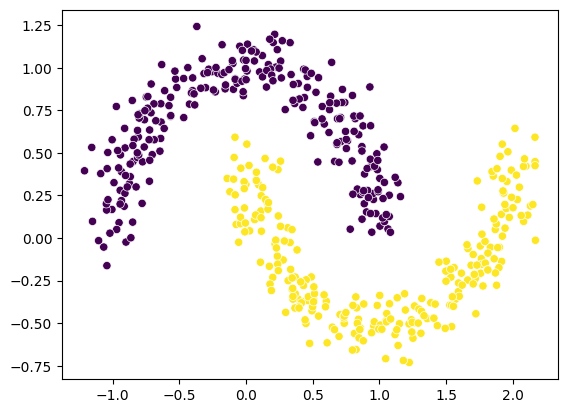

In [3]:
sns.scatterplot(x=X[:, 0], y=X[:,1], c=y)

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

<Axes: >

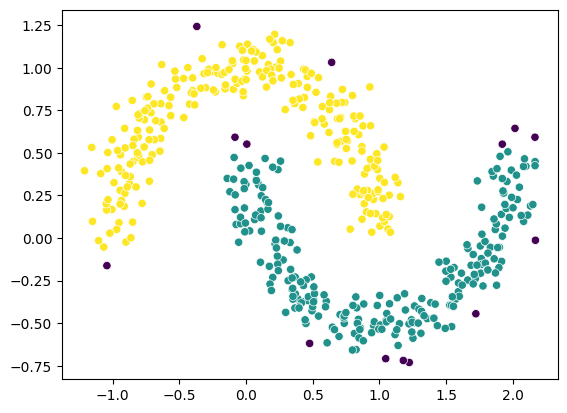

In [5]:
dbs = DBSCAN(
    eps=0.18,
    min_samples=5
)

lables = dbs.fit_predict(X_scaled)

sns.scatterplot(x=X[:, 0], y=X[:,1], c=lables)

### Thyroid - Isolation Forest

In [18]:
import pandas as pd

df = pd.read_csv("../../Data-Files/thyroid_dataset.csv")
df.head()

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured,Outlier_label
0,0.45,1,0,0,0,0,0,0,0,0,...,0,0,0,0,61.0,6.0,23.0,87.0,26.0,o
1,0.61,0,0,0,0,1,0,0,0,0,...,0,0,0,0,29.0,15.0,61.0,96.0,64.0,o
2,0.16,0,1,0,0,0,0,0,0,0,...,0,1,0,0,29.0,19.0,58.0,103.0,56.0,o
3,0.85,0,0,0,0,0,0,0,0,0,...,0,0,0,0,114.0,3.0,24.0,61.0,39.0,o
4,0.75,1,0,0,0,0,0,0,0,0,...,0,0,0,0,49.0,3.0,5.0,116.0,4.0,o


In [29]:
X = df.drop(columns=["Outlier_label"])
y = df["Outlier_label"]

x_scaler = scaler.fit_transform(X)

In [31]:
from sklearn.ensemble import IsolationForest

isf = IsolationForest(
    n_estimators=200,
    contamination=0.0361,
    random_state=42
)

lables = isf.fit_predict(x_scaler)

In [32]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2,
)

x_pca = pca.fit_transform(x_scaler)

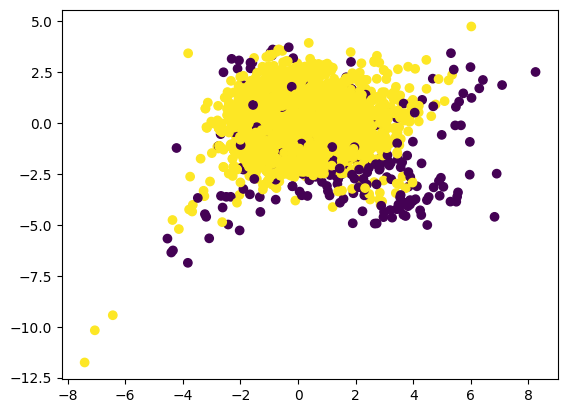

In [33]:
plt.scatter(x=x_pca[:, 0], y=x_pca[:, 1], c=lables)

In [34]:
import numpy as np

n_ano = np.sum(lables == -1)
n_normal = np.sum(lables == 1)

print(n_ano, n_normal)

250 6666


### LOF

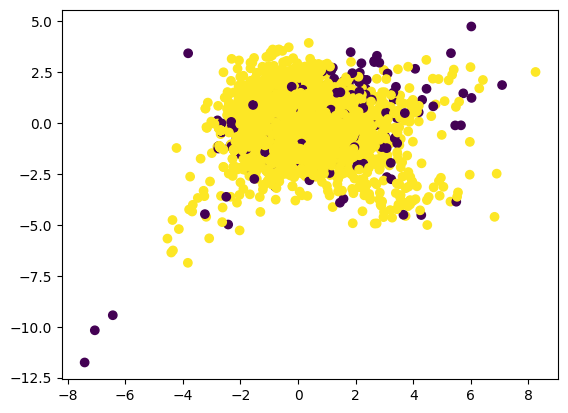

In [36]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(contamination=0.0361)

lables = lof.fit_predict(x_scaler)
plt.scatter(x=x_pca[:, 0], y=x_pca[:, 1], c=lables)

In [37]:
n_ano = np.sum(lables == -1)
n_normal = np.sum(lables == 1)

print(n_ano, n_normal)

250 6666
